In [2]:
from dataclasses import dataclass
from llvmlite.utils import os
import numpy as np

from openpyxl import load_workbook
from openpyxl.worksheet.worksheet import Worksheet
import matplotlib.pyplot as plt
import pyinflat


In [4]:
@dataclass
class Dataset:
    k: np.ndarray
    spectra: np.ndarray
    params: np.ndarray
    params_name: tuple[str, ...]

    @staticmethod
    def from_workbook(ws: Worksheet) -> Dataset:
        assert ws.cell(row=1, column=1).value is not None
        k_start = 2
        while ws.cell(row=1, column=k_start).value is None:
            k_start += 1
        k_end = k_start
        while ws.cell(row=1, column=k_end).value is not None:
            k_end += 1
        k = np.array([ws.cell(row=1, column=i).value for i in range(k_start, k_end)])

        param_names: list[str] = []
        param_count = 0
        while ws.cell(row=2, column=param_count + 1).value != 'P_R':
            param_names.append(str(ws.cell(row=2, column=param_count + 1).value))
            param_count += 1

        spectra: list[list[float]] = []
        params: list[list[float]] = []
        row = 3
        while ws.cell(row=row, column=1).value is not None:
            params.append([float(ws.cell(row=row, column=param_count + 1).value) for param_count in range(len(param_names))])
            spectra.append([float(ws.cell(row=row, column=i).value) for i in range(k_start, k_end)])
            row += 1

        return Dataset(k, np.array(spectra), np.array(params), tuple(param_names))

In [12]:
def check_one_file(path: str):
    wb = load_workbook(os.path.expanduser(path)).active
    assert wb is not None
    a = Dataset.from_workbook(wb)

    chosen_spec = a.spectra[0]
    omega_sigw = pyinflat.sigw_energy_density(a.k, chosen_spec)

    figure = plt.figure()
    ax = figure.subplots()
    ax.plot(a.k, chosen_spec)
    ax.plot(a.k, omega_sigw)
    ax.set_yscale('log')
    ax.set_xscale('log')
    return figure

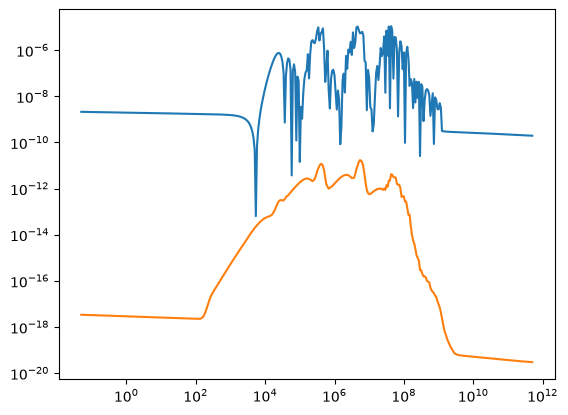

In [15]:
fig = check_one_file('~/Downloads/Staro+step(11.28).xlsx')

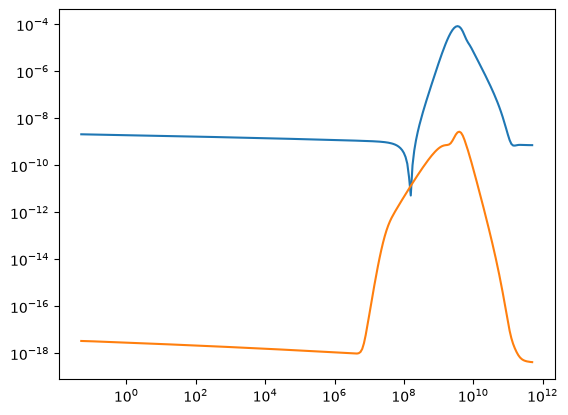

In [16]:
fig = check_one_file('~/Downloads/KKLT+Gauss_sigma0.02(11.27).xlsx')

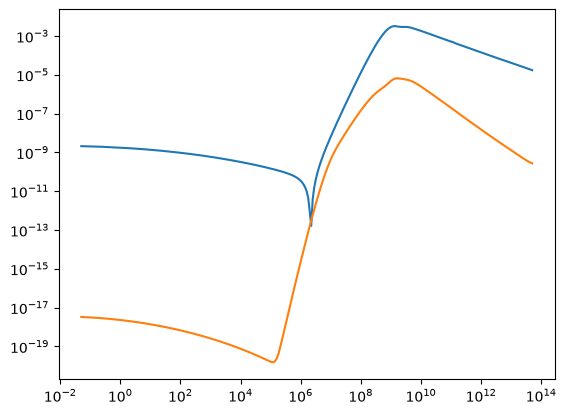

In [17]:
fig = check_one_file('~/Downloads/double inflection(11.29).xlsx')